In [4]:
import yfinance as yf
import pandas as pd

df = yf.download('SPY', start='2005-01-01', end='2025-12-31', auto_adjust=True, progress=False)
prices = df['Close']
if isinstance(prices, pd.DataFrame):
    prices = prices.iloc[:, 0]
prices = prices.rename("Close")


In [5]:
print(len(prices), prices.index.min().date(), prices.index.max().date())
print("missing", prices.isna().sum())
print(prices.head(3))
print(prices.tail(3))


5282 2005-01-03 2025-12-30
missing 0
Date
2005-01-03    80.973541
2005-01-04    79.984100
2005-01-05    79.432144
Name: Close, dtype: float64
Date
2025-12-26    684.960022
2025-12-29    682.519043
2025-12-30    681.685547
Name: Close, dtype: float64


In [6]:
prices.to_csv("data/spy.csv")
pd.read_csv("data/spy.csv", index_col="Date",
parse_dates=True).head()

,Close
Date,
2005-01-03,80.973541
2005-01-04,79.984100
2005-01-05,79.432144
2005-01-06,79.835991
2005-01-07,79.721611


49.5575065612793 2009-03-09 00:00:00


<Axes: title={'center': 'SPY Price'}, xlabel='Date', ylabel='Price'>

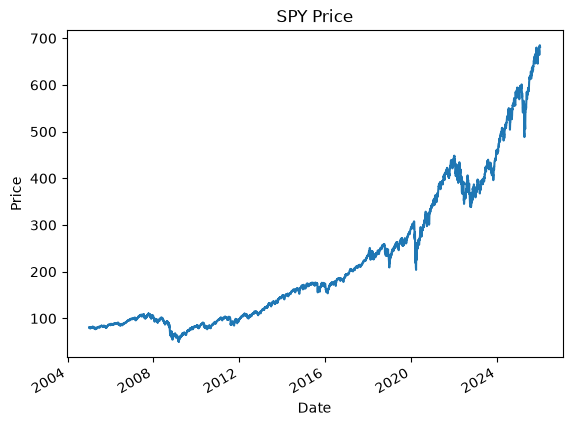

In [12]:
print(prices.min(), prices.idxmin())
prices.plot(ylabel ="Price", title="SPY Price")


<Axes: title={'center': 'SPY Price (log scale)'}, xlabel='Date', ylabel='Price'>

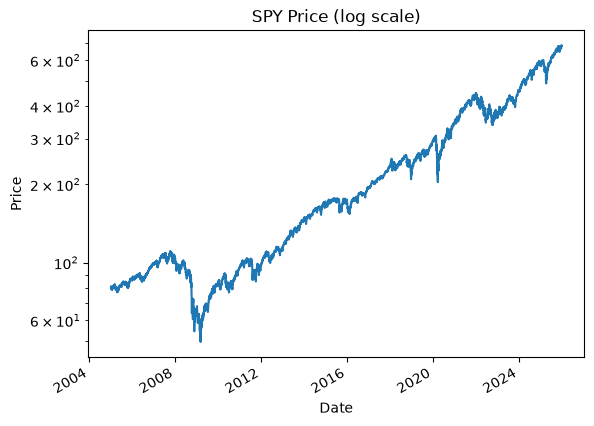

In [14]:
prices.plot(logy=True, ylabel ="Price", title="SPY Price (log scale)")


In [ ]:
#rows: 5283  lowest price date: 2009-03-09

In [3]:
import pandas as pd
import numpy as np
prices = pd.read_csv("data/spy.csv", index_col="Date", parse_dates=True)["Close"]
print(len(prices), prices.index[0].date(), prices.index[-1].date())


5282 2005-01-03 2025-12-30


8.41862090096978


<Axes: title={'center': 'SPY Equity Curve (log scale)'}, xlabel='Date', ylabel='Equity'>

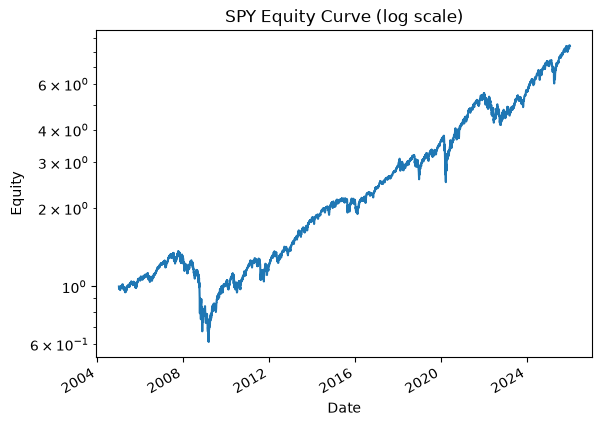

In [ ]:
daily_ret = prices.pct_change().fillna(0)   # % change from yday; day 1 is 0% change
equity = (1 + daily_ret).cumprod()  # cumulative product of daily returns
print(equity.iloc[-1])
equity.plot(logy=True, ylabel="Equity", title="SPY Equity Curve (log scale)")

# final equity: 8.41862090096978

In [ ]:
#confirmation of final equity
val = 1.0
for i in range(1, len(prices)):
    val *= prices.iloc[i] / prices.iloc[i-1]
print(val)  # should be same as equity.iloc[-1]

#  returns 8.41862090096978. correct!


8.41862090096978


In [7]:
print("worst: ", daily_ret.idxmin().date(), round(daily_ret.min(), 3))
print("best: ", daily_ret.idxmax().date(), round(daily_ret.max(), 3))


worst:  2020-03-16 -0.109
best:  2008-10-13 0.145


In [5]:
# check of +10% and -10% returns
(1 + pd.Series([0.1, -0.10])).cumprod()

0    1.10
1    0.99
dtype: float64

In [1]:
import pandas as pd
import numpy as np
prices = pd.read_csv("data/spy.csv", index_col="Date", parse_dates=True)["Close"]
daily_ret = prices.pct_change().fillna(0)
print(len(prices))

5282


In [2]:
sma = prices.rolling(200).mean()      # 200-day simple moving average; the first 199 days are blank (NaN)
signal = (prices > sma).astype(int)  # True/false -> 1/0
position = signal.shift(1).fillna(0)  # act TMRW on TODAYS signal --> eliminates look ahead bias
pd.DataFrame({"price" : prices, "sma" : sma, "signal" : signal, "position" : position}).iloc[198:206]


,price,sma,signal,position
Date,,,,
2005-10-14,80.856506,NaN,0,0.0
2005-10-17,81.156311,81.206419,0,0.0
2005-10-18,80.277328,81.202938,0,0.0
2005-10-19,81.612808,81.211081,1,0.0
2005-10-20,80.175148,81.214796,0,1.0
2005-10-21,80.488556,81.218059,0,0.0
2005-10-24,81.735428,81.228128,1,0.0
2005-10-25,81.571915,81.235495,1,1.0


In [3]:
fake = (1 + signal * daily_ret).cumprod()  # no shift: cheats
real = (1 + position * daily_ret).cumprod()  # shift: honest
print("fake:", fake.iloc[-1], " real:" , real.iloc[-1], " buy & hold: 8.42")

# fake is impossible as it gives the returns of a strategy that trades on the same day as the signal is generated, which is not realistic. The real strategy, which shifts the position to act on the signal the next day, gives a more accurate representation of what could be achieved in practice.

fake: 43.41260360764106  real: 5.499159828445307  buy & hold: 8.42


In [4]:
print("time in market:", position.mean())
changes = position.diff()
changes[changes != 0].loc["2007":"2009"]      # -1 = exit to cash, +1 = buy back in

# Exit to cash (for the crash): 2008-05-22
# Re-entry into SPY:            2009-06-01
# Whipsaws before the exit: 20 back-and-forth switches between 2007-08-06 and 2008-05-16,
# because the price kept crossing back and forth over the 200-day average. 

time in market: 0.7631578947368421


Date
2007-08-06   -1.0
2007-08-07    1.0
2007-08-15   -1.0
2007-08-20    1.0
2007-08-21   -1.0
2007-08-22    1.0
2007-08-29   -1.0
2007-08-30    1.0
2007-11-09   -1.0
2007-11-14    1.0
2007-11-16   -1.0
2007-12-03    1.0
2007-12-05   -1.0
2007-12-06    1.0
2007-12-17   -1.0
2007-12-24    1.0
2007-12-31   -1.0
2008-05-07    1.0
2008-05-08   -1.0
2008-05-16    1.0
2008-05-22   -1.0
2009-06-01    1.0
Name: Close, dtype: float64

In [ ]:
from backtest import run_strategy
res = run_strategy(prices, 200)
res.tail()

print((1 + res["strategy"]).cumprod().iloc[-1])

# growth of $1 was 5.17 with 0.0005 cost per trade, but drops more than half to 2.59 with 0.005 cost per trade.

5.171047769093166


In [6]:
years = len(res) / 252
print("200-day: trades", res["trades"].sum(), " per year", round(res["trades"].sum() / years, 1),
      " growth of $1:", round((1 + res["strategy"]).cumprod().iloc[-1], 2))
r20 = run_strategy(prices, 20)
print("20-day:  trades", r20["trades"].sum(), " total cost", round((r20["trades"] * 0.0005).sum(), 3),
      " growth of $1:", round((1 + r20["strategy"]).cumprod().iloc[-1], 2))

# 20-day rule makes 472 more trades. 
# neither rule beats buy-and-hold, which grows $1 to $8.42 over the period. The 20-day rule is whipsawing too much, and the 200-day rule is too slow to react to the market.

200-day: trades 123.0  per year 5.9  growth of $1: 5.17
20-day:  trades 595.0  total cost 0.298  growth of $1: 1.9
